# Gold Market Volatility Forecasting
## Exploratory analysis, model comparison and final evaluation

**Project:** Gold Market Volatility Forecasting  
**Market data:** COMEX gold futures continuous-contract proxy (`GC=F`) from Yahoo Finance  
**Prediction task:** Estimate realized volatility over the next five observed trading sessions.

This notebook presents the analysis and evaluation results produced by the project's Python scripts. The scripts remain the source of truth for data preparation, model training, tuning and final evaluation; this notebook makes the workflow and findings easy for a reviewer to inspect.

> **Important scope note:** This is a volatility-estimation project, not a buy/sell signal or investment recommendation. `GC=F` is a continuous gold-futures proxy and is not identical to XAUUSD spot. Futures contract rolls and settlement conventions can affect historical OHLC observations.


## 1. Problem definition

Gold prices can move sharply during periods of macroeconomic uncertainty, interest-rate changes, currency movements and geopolitical events. A volatility estimate can help describe the level of market risk expected over a short horizon.

The project asks:

**Can historical daily gold-futures OHLC data and lagged market features estimate realized volatility over the next five observed trading sessions?**

The model predicts a continuous volatility value. It does not predict the direction of gold prices.

### Target definition

Let the daily close-to-close log return be:

\[
r_t = \log\left(\frac{C_t}{C_{t-1}}\right)
\]

The target at time \(t\) is:

\[
\text{FutureVol}_{t,5}
= 100 \times \sqrt{\sum_{i=1}^{5} r_{t+i}^{2}}
\]

This is the five-session forward realized volatility, expressed as a percentage. “Five sessions” means five observed rows in the trading data, not five calendar days.


## 2. Project workflow

1. Download and inspect daily gold-futures OHLC data.
2. Check missing values, duplicate dates, zero-volume records and OHLC consistency.
3. Engineer return, range, momentum and rolling-volatility features.
4. Create chronological train, validation and test partitions, with a five-row purge between partitions to reduce overlap between forward-looking targets.
5. Compare a mean baseline, a persistence baseline, linear regression, decision tree, random forest and XGBoost.
6. Tune tree-based models using time-series cross-validation.
7. Investigate outliers and questionable OHLC records.
8. Retrain the selected XGBoost model on train + validation data and evaluate it once on the held-out test period.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root whether Jupyter was started from the root or notebooks/.
search_locations = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in search_locations
     if (path / "data" / "raw" / "gold_daily.csv").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/gold_daily.csv. "
        "Open this notebook from the project root or its notebooks/ folder."
    )

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"

print("Project root:", PROJECT_ROOT)
print("Raw data:", DATA_RAW)
print("Processed data:", DATA_PROCESSED)
print("Reports:", REPORTS)


Project root: E:\Study\Self_Study\Ml Zoomcamp\midterm-gold-volatility
Raw data: E:\Study\Self_Study\Ml Zoomcamp\midterm-gold-volatility\data\raw
Processed data: E:\Study\Self_Study\Ml Zoomcamp\midterm-gold-volatility\data\processed
Reports: E:\Study\Self_Study\Ml Zoomcamp\midterm-gold-volatility\reports


In [2]:
def read_csv_with_dates(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    date_column = next(
        (column for column in df.columns if column.lower() == "date"),
        None
    )
    if date_column is not None:
        df[date_column] = pd.to_datetime(df[date_column], errors="coerce")
        df = df.sort_values(date_column).reset_index(drop=True)
    return df


def read_optional_csv(path: Path):
    if path.exists():
        return read_csv_with_dates(path)
    print(f"Not found (optional output): {path.relative_to(PROJECT_ROOT)}")
    return None


raw = read_csv_with_dates(DATA_RAW / "gold_daily.csv")
features = read_csv_with_dates(DATA_PROCESSED / "gold_volatility_features.csv")

train = read_optional_csv(DATA_PROCESSED / "train.csv")
validation = read_optional_csv(DATA_PROCESSED / "validation.csv")
test = read_optional_csv(DATA_PROCESSED / "test.csv")

print(f"Raw rows: {len(raw):,}")
print(f"Feature rows: {len(features):,}")
display(raw.head())


Raw rows: 6,568
Feature rows: 6,503


,Date,Open,High,Low,Close,Volume
0,2000-08-30,273.899994,273.899994,273.899994,273.899994,0
1,2000-08-31,274.799988,278.299988,274.799988,278.299988,0
2,2000-09-01,277.000000,277.000000,277.000000,277.000000,0
3,2000-09-05,275.799988,275.799988,275.799988,275.799988,2
4,2000-09-06,274.200012,274.200012,274.200012,274.200012,0


## 3. Dataset overview

The raw dataset contains daily open, high, low, close and volume observations. Volume is excluded from the model features because the source contains many zero-volume and repeated OHLC records, making volume less reliable as a predictor.

The data is a long historical series, so a chronological split is more appropriate than a random split. A random split could mix future market regimes into the training data.


In [3]:
date_col = "Date"
required_raw_columns = {"Date", "Open", "High", "Low", "Close", "Volume"}
missing_raw_columns = required_raw_columns - set(raw.columns)

if missing_raw_columns:
    raise ValueError(f"Missing expected raw columns: {sorted(missing_raw_columns)}")

overview = pd.DataFrame({
    "Item": [
        "Number of observations",
        "First date",
        "Last date",
        "Missing values (all columns)",
        "Duplicate dates",
        "Zero-volume records",
        "Identical OHLC records"
    ],
    "Value": [
        len(raw),
        raw["Date"].min().date(),
        raw["Date"].max().date(),
        int(raw.isna().sum().sum()),
        int(raw["Date"].duplicated().sum()),
        int(raw["Volume"].eq(0).sum()),
        int(raw[["Open", "High", "Low", "Close"]].nunique(axis=1).eq(1).sum())
    ]
})

display(overview)
display(raw[["Open", "High", "Low", "Close", "Volume"]].describe().T)


,Item,Value
0,Number of observations,6568
1,First date,2000-08-30
2,Last date,2026-10-30
3,Missing values (all columns),0
4,Duplicate dates,0
5,Zero-volume records,418
6,Identical OHLC records,751


,count,mean,std,min,25%,50%,75%,max
Open,6568.0,1357.895615,923.593603,255.000000,660.650009,1261.200012,1731.425018,5415.700195
High,6568.0,1367.174574,934.489265,256.100006,662.399994,1267.750000,1741.325043,5586.200195
Low,6568.0,1348.111358,912.140519,255.000000,659.074982,1255.300049,1719.000000,5272.899902
Close,6568.0,1357.845752,923.628810,255.100006,660.650009,1262.000000,1728.900024,5318.399902
Volume,6568.0,51427.190926,92483.457663,0.000000,29.000000,199.500000,88773.500000,570055.000000


## 4. Data-quality checks

An OHLC row is flagged when the high is below the open or close, the low is above the open or close, or the high is below the low.

These checks identify records that deserve investigation. They do not automatically prove that a record is erroneous: futures settlement conventions, contract stitching and source-specific data handling can produce unusual OHLC relationships.


In [4]:
ohlc_violations = {
    "high_below_open": raw["High"] < raw["Open"],
    "high_below_close": raw["High"] < raw["Close"],
    "low_above_open": raw["Low"] > raw["Open"],
    "low_above_close": raw["Low"] > raw["Close"],
    "high_below_low": raw["High"] < raw["Low"],
}

violation_summary = pd.DataFrame({
    "Violation": list(ohlc_violations.keys()),
    "Count": [int(mask.sum()) for mask in ohlc_violations.values()]
})

invalid_ohlc_mask = np.logical_or.reduce(
    [mask.to_numpy() for mask in ohlc_violations.values()]
)
invalid_ohlc_rows = raw.loc[invalid_ohlc_mask].copy()

print("Unique rows with at least one OHLC consistency flag:",
      f"{len(invalid_ohlc_rows):,}")
display(violation_summary)

if not invalid_ohlc_rows.empty:
    print("Flagged date range:",
          invalid_ohlc_rows["Date"].min().date(),
          "to",
          invalid_ohlc_rows["Date"].max().date())


Unique rows with at least one OHLC consistency flag: 441


,Violation,Count
0,high_below_open,23
1,high_below_close,223
2,low_above_open,33
3,low_above_close,207
4,high_below_low,1


Flagged date range: 2001-02-13 to 2011-11-14


In [5]:
# Inspect the questionable records rather than deleting them automatically.
display(invalid_ohlc_rows.head(10))


,Date,Open,High,Low,Close,Volume
113,2001-02-13,261.000000,261.000000,261.000000,260.299988,0
661,2003-04-29,333.000000,333.000000,333.000000,333.700012,1
662,2003-04-30,337.000000,337.000000,337.000000,339.100006,6
663,2003-05-01,339.000000,339.000000,339.000000,342.100006,1
664,2003-05-02,342.100006,342.200012,342.200012,341.000000,1
667,2003-05-07,342.100006,342.100006,342.100006,341.899994,5
668,2003-05-08,344.600006,344.600006,344.600006,348.399994,6
669,2003-05-09,348.299988,348.200012,348.200012,348.600006,1
672,2003-05-14,350.100006,350.100006,350.100006,352.299988,1
674,2003-05-16,352.600006,352.700012,352.700012,354.700012,1


## 5. Exploratory data analysis

The following charts show the long-term gold-futures price history, daily close-to-close returns and the distribution of the five-session forward-volatility target.


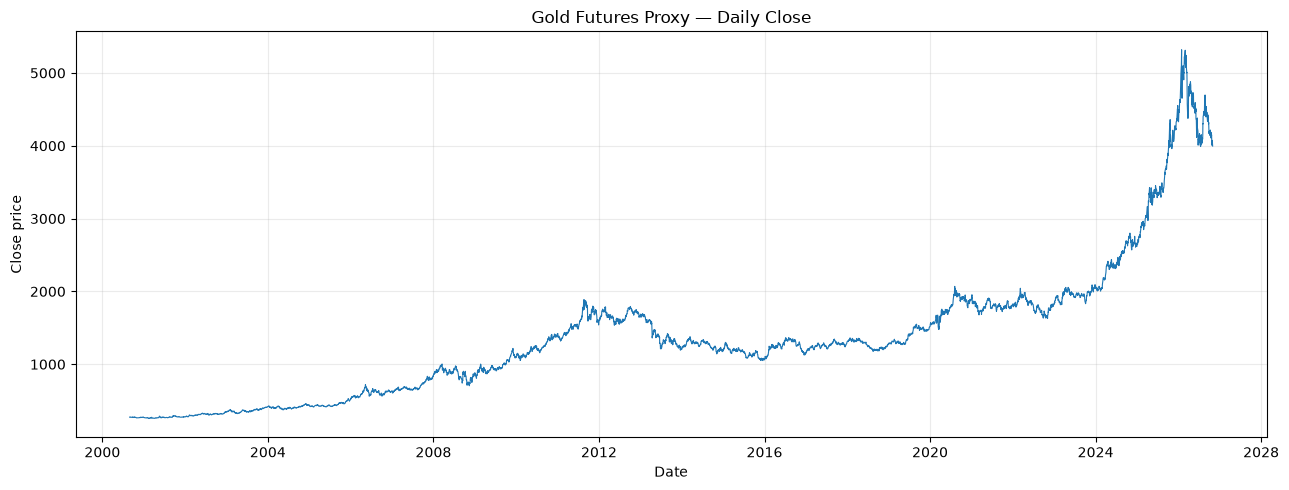

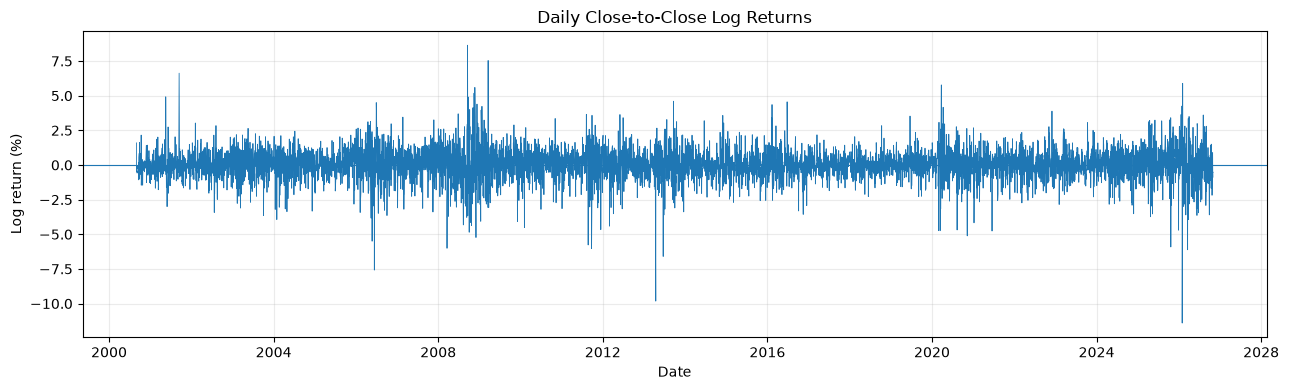

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(raw["Date"], raw["Close"], linewidth=0.8)
ax.set_title("Gold Futures Proxy — Daily Close")
ax.set_xlabel("Date")
ax.set_ylabel("Close price")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

raw["daily_log_return_pct"] = (
    np.log(raw["Close"] / raw["Close"].shift(1)) * 100
)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(raw["Date"], raw["daily_log_return_pct"], linewidth=0.6)
ax.axhline(0, linewidth=0.8)
ax.set_title("Daily Close-to-Close Log Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Log return (%)")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


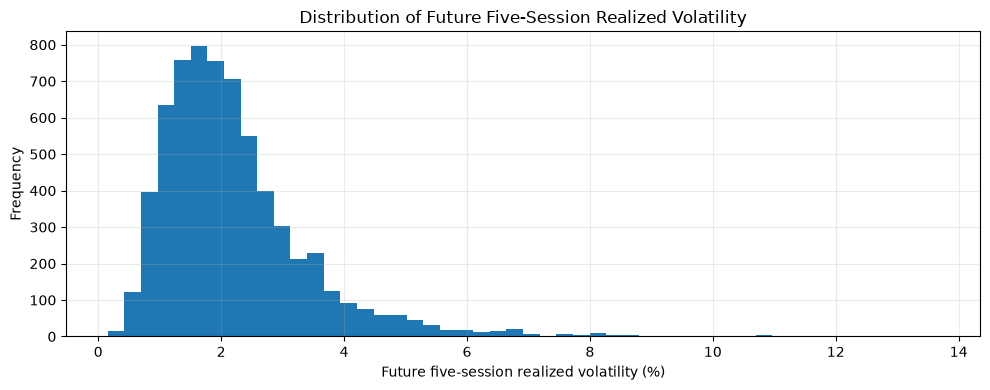

,target_summary
count,6503.000000
mean,2.215740
std,1.240009
min,0.154228
25%,1.405882
50%,1.961408
75%,2.670235
max,13.670741


In [7]:
TARGET = "target_future_5d_volatility_pct"

if TARGET not in features.columns:
    raise ValueError(
        f"Expected target column '{TARGET}' was not found. "
        f"Available columns: {features.columns.tolist()}"
    )

fig, ax = plt.subplots(figsize=(10, 4))
features[TARGET].dropna().hist(bins=50, ax=ax)
ax.set_title("Distribution of Future Five-Session Realized Volatility")
ax.set_xlabel("Future five-session realized volatility (%)")
ax.set_ylabel("Frequency")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

display(features[TARGET].describe().to_frame("target_summary"))


## 6. Feature engineering

The model uses 17 features derived from price behaviour:

- Daily return, overnight gap, intraday range and open-to-close return.
- Lagged daily returns over 1, 2, 3, 5 and 10 sessions.
- Rolling realized volatility over 5, 10, 20 and 60 sessions.
- Momentum over 5, 10, 20 and 60 sessions.

Volume is not included. The feature list below is also the expected input schema for the final model.


In [8]:
FEATURE_COLUMNS = [
    "current_return_pct",
    "overnight_gap_pct",
    "intraday_range_pct",
    "open_close_return_pct",
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "return_lag_5",
    "return_lag_10",
    "realized_vol_5d",
    "realized_vol_10d",
    "realized_vol_20d",
    "realized_vol_60d",
    "momentum_5d",
    "momentum_10d",
    "momentum_20d",
    "momentum_60d",
]

missing_features = [column for column in FEATURE_COLUMNS if column not in features.columns]
if missing_features:
    raise ValueError(f"Missing expected model features: {missing_features}")

print(f"Model feature count: {len(FEATURE_COLUMNS)}")
display(features[FEATURE_COLUMNS + [TARGET]].describe().T)


Model feature count: 17


,count,mean,std,min,25%,50%,75%,max
current_return_pct,6503.0,0.041695,1.134974,-11.405996,-0.491479,0.052032,0.637767,8.643166
overnight_gap_pct,6503.0,0.045274,0.604075,-6.045979,-0.179218,0.017424,0.251186,6.623996
intraday_range_pct,6503.0,1.127332,1.015816,-0.111659,0.452087,0.978933,1.543673,16.433801
open_close_return_pct,6503.0,-0.003579,0.970729,-13.113657,-0.362536,0.000000,0.428484,8.963758
return_lag_1,6503.0,0.041929,1.134854,-11.405996,-0.491299,0.052463,0.637767,8.643166
return_lag_2,6503.0,0.042230,1.134524,-11.405996,-0.490246,0.052463,0.637767,8.643166
return_lag_3,6503.0,0.042238,1.134525,-11.405996,-0.490246,0.052463,0.637767,8.643166
return_lag_5,6503.0,0.042415,1.134494,-11.405996,-0.489205,0.052523,0.637767,8.643166
return_lag_10,6503.0,0.042549,1.134135,-11.405996,-0.489038,0.052914,0.637397,8.643166
realized_vol_5d,6503.0,2.215393,1.239999,0.154228,1.405882,1.960996,2.667620,13.670741


## 7. Chronological train, validation and test split

The project uses a time-ordered split:

| Partition | Rows | Date range |
|---|---:|---|
| Train | 4,547 | 2000-11-27 to 2019-01-16 |
| Validation | 970 | 2019-01-25 to 2022-11-29 |
| Test | 976 | 2022-12-07 to 2026-10-23 |

Five observations are purged between partitions because the target looks five observed sessions into the future. This reduces overlap between target windows across partition boundaries.


In [9]:
def split_summary(name, frame):
    if frame is None:
        return {
            "Partition": name,
            "Rows": None,
            "First date": None,
            "Last date": None
        }
    return {
        "Partition": name,
        "Rows": len(frame),
        "First date": frame["Date"].min().date(),
        "Last date": frame["Date"].max().date()
    }


split_table = pd.DataFrame([
    split_summary("Train", train),
    split_summary("Validation", validation),
    split_summary("Test", test)
])

display(split_table)


,Partition,Rows,First date,Last date
0,Train,4547,2000-11-27,2019-01-16
1,Validation,970,2019-01-25,2022-11-29
2,Test,976,2022-12-07,2026-10-23


## 8. Model comparison and hyperparameter tuning

Several regression approaches were evaluated. The initial comparison included a mean baseline, a persistence baseline, linear regression, a decision tree, random forest and XGBoost.

The tuned tree-based models were selected using time-series cross-validation with a five-row gap. The held-out test set was not used for model selection.

The CSV tables below are generated by the project's training and tuning scripts.


In [10]:
initial_comparison = read_optional_csv(
    DATA_PROCESSED / "model_comparison.csv"
)
tuned_comparison = read_optional_csv(
    DATA_PROCESSED / "tuned_model_comparison.csv"
)

if initial_comparison is not None:
    print("Initial validation model comparison")
    display(initial_comparison)

if tuned_comparison is not None:
    print("Tuned validation model comparison")
    display(tuned_comparison)


Initial validation model comparison


,Model,RMSE,MAE,R2
0,XGBoost,1.051452,0.772848,0.143724
1,Random Forest,1.053123,0.779337,0.140999
2,Linear Regression,1.053676,0.783692,0.140097
3,Decision Tree,1.094373,0.785641,0.072389


Tuned validation model comparison


,Model,RMSE,MAE,R2
0,Tuned XGBoost,1.037870,0.760078,0.165703
1,Tuned Random Forest,1.043878,0.766940,0.156014


## 9. Final held-out test evaluation

After selecting XGBoost, the final evaluation script retrained it using the combined training and validation data, then evaluated it on the untouched test partition.

Reported test results:

| Model | RMSE | MAE | R² |
|---|---:|---:|---:|
| Mean baseline | 1.4683 | 0.9692 | -0.0370 |
| Five-session persistence | 1.5002 | 1.0214 | -0.0826 |
| Final XGBoost | **1.1692** | **0.8071** | **0.3424** |

The final XGBoost model reduced RMSE by approximately **20.37%** relative to the mean baseline on this test period.

These are historical test-period results, not a guarantee of future forecasting performance.


In [11]:
final_metrics = pd.DataFrame([
    {"Model": "Mean baseline", "RMSE": 1.4683, "MAE": 0.9692, "R2": -0.0370},
    {"Model": "Five-session persistence", "RMSE": 1.5002, "MAE": 1.0214, "R2": -0.0826},
    {"Model": "Final XGBoost", "RMSE": 1.1692, "MAE": 0.8071, "R2": 0.3424},
])

metrics_file = REPORTS / "final_test_metrics.csv"
if metrics_file.exists():
    print("Saved final test metrics from the project:")
    display(read_csv_with_dates(metrics_file))
else:
    print("Using the final metrics recorded in the project run summary.")

display(final_metrics)

baseline_rmse = final_metrics.loc[
    final_metrics["Model"] == "Mean baseline", "RMSE"
].iloc[0]
model_rmse = final_metrics.loc[
    final_metrics["Model"] == "Final XGBoost", "RMSE"
].iloc[0]

rmse_improvement_pct = (baseline_rmse - model_rmse) / baseline_rmse * 100
print(f"RMSE improvement over mean baseline: {rmse_improvement_pct:.2f}%")


Saved final test metrics from the project:


,Model,RMSE,MAE,R2
0,Mean Baseline,1.468306,0.969215,-0.037042
1,5-Day Volatility Persistence,1.500190,1.021396,-0.082568
2,Final XGBoost,1.169230,0.807098,0.342399


,Model,RMSE,MAE,R2
0,Mean baseline,1.4683,0.9692,-0.0370
1,Five-session persistence,1.5002,1.0214,-0.0826
2,Final XGBoost,1.1692,0.8071,0.3424


RMSE improvement over mean baseline: 20.37%


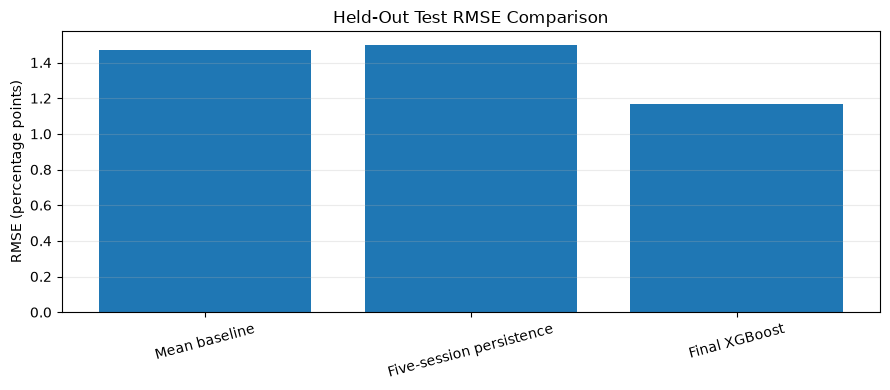

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(final_metrics["Model"], final_metrics["RMSE"])
ax.set_title("Held-Out Test RMSE Comparison")
ax.set_ylabel("RMSE (percentage points)")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 10. Test predictions and residual analysis

If the final evaluation script has saved `reports/test_predictions.csv`, this section plots actual versus predicted volatility and examines the residuals. The code detects common column-name variants so the notebook can accommodate the saved prediction file's schema.


In [13]:
predictions_path = REPORTS / "test_predictions.csv"
predictions = read_optional_csv(predictions_path)

def find_column(frame, candidates):
    lookup = {column.lower(): column for column in frame.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None


if predictions is not None:
    actual_col = find_column(
        predictions,
        ["actual", "y_true", "actual_value", TARGET, "target"]
    )
    predicted_col = find_column(
        predictions,
        ["prediction", "predicted", "y_pred", "predicted_value",
         "predicted_volatility", "xgboost_prediction"]
    )
    prediction_date_col = find_column(predictions, ["date"])

    print("Prediction columns:", predictions.columns.tolist())

    if actual_col and predicted_col:
        plot_data = predictions.copy()
        if prediction_date_col:
            plot_data = plot_data.sort_values(prediction_date_col)

        fig, ax = plt.subplots(figsize=(13, 5))
        x_values = (
            plot_data[prediction_date_col]
            if prediction_date_col
            else np.arange(len(plot_data))
        )
        ax.plot(x_values, plot_data[actual_col], label="Actual", linewidth=0.9)
        ax.plot(x_values, plot_data[predicted_col], label="Predicted", linewidth=0.9)
        ax.set_title("Actual vs Predicted Five-Session Volatility — Test Set")
        ax.set_xlabel("Date" if prediction_date_col else "Test observation")
        ax.set_ylabel("Volatility (%)")
        ax.legend()
        ax.grid(True, alpha=0.25)
        plt.tight_layout()
        plt.show()

        residuals = plot_data[actual_col] - plot_data[predicted_col]

        fig, ax = plt.subplots(figsize=(9, 4))
        residuals.hist(bins=40, ax=ax)
        ax.set_title("Test Residual Distribution")
        ax.set_xlabel("Actual - predicted (%)")
        ax.set_ylabel("Frequency")
        ax.grid(True, alpha=0.25)
        plt.tight_layout()
        plt.show()

        display(residuals.describe().to_frame("residual_summary"))
    else:
        print(
            "Could not identify actual and prediction columns automatically. "
            "Inspect the displayed column names and adjust the candidate lists."
        )
else:
    print("Prediction file is not available yet.")


Prediction columns: ['Date', 'Actual_Volatility', 'Predicted_Volatility', 'Residual', 'Absolute_Error']
Could not identify actual and prediction columns automatically. Inspect the displayed column names and adjust the candidate lists.


## 11. Feature importance

The project examines both native XGBoost feature importance and validation-set permutation importance. Permutation importance is particularly useful here because it measures the impact of shuffling a feature on validation performance.

The leading validation features were longer-window realized volatility measures, especially `realized_vol_60d` and `realized_vol_20d`. This suggests that recent volatility regimes carry useful information about near-term future volatility.


,Feature,Importance
0,realized_vol_20d,0.223893
1,realized_vol_10d,0.167731
2,realized_vol_60d,0.157769
3,momentum_60d,0.061836
4,momentum_20d,0.046359
5,realized_vol_5d,0.043874
6,momentum_5d,0.037773
7,intraday_range_pct,0.033196
8,momentum_10d,0.029073
9,return_lag_3,0.028267


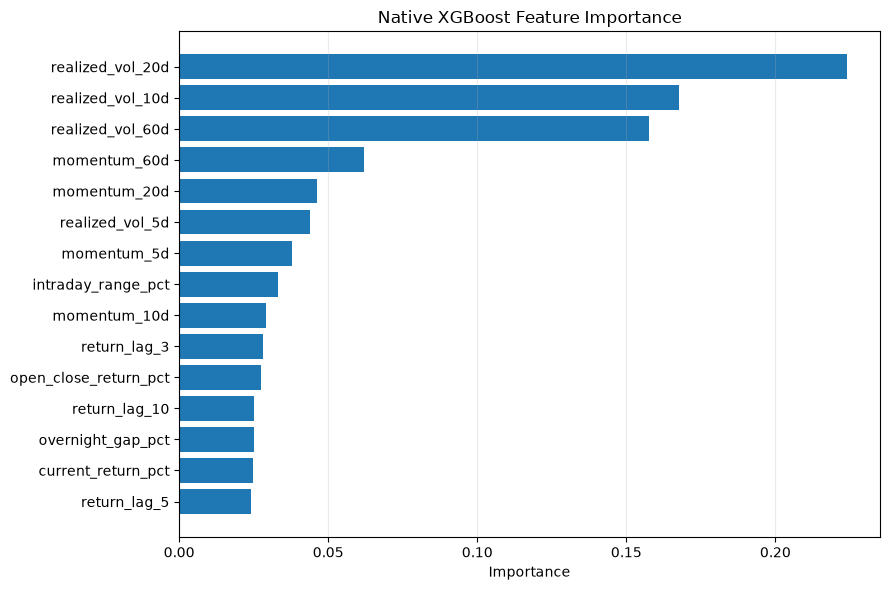

,Feature,Importance
0,realized_vol_60d,0.035764
1,realized_vol_20d,0.028066
2,momentum_60d,0.015727
3,intraday_range_pct,0.008777
4,momentum_20d,0.008641
5,realized_vol_10d,0.008365
6,momentum_5d,0.003972
7,return_lag_3,0.001317
8,overnight_gap_pct,0.000759
9,return_lag_5,0.000392


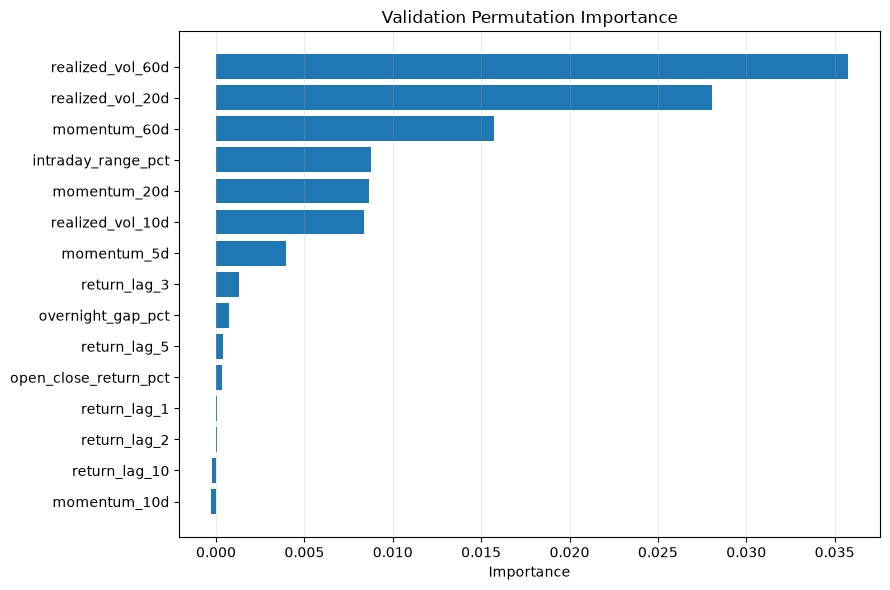

In [14]:
def plot_importance_file(path, title, feature_candidates, value_candidates, top_n=15):
    frame = read_optional_csv(path)
    if frame is None:
        return

    feature_col = find_column(frame, feature_candidates)
    value_col = find_column(frame, value_candidates)

    if feature_col is None or value_col is None:
        print(f"Could not identify feature/value columns in {path.name}.")
        print("Available columns:", frame.columns.tolist())
        display(frame.head())
        return

    plot_frame = frame[[feature_col, value_col]].copy()
    plot_frame[value_col] = pd.to_numeric(plot_frame[value_col], errors="coerce")
    plot_frame = plot_frame.dropna().sort_values(value_col).tail(top_n)

    display(plot_frame.sort_values(value_col, ascending=False))

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(plot_frame[feature_col], plot_frame[value_col])
    ax.set_title(title)
    ax.set_xlabel(value_col)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()


plot_importance_file(
    DATA_PROCESSED / "native_feature_importance.csv",
    "Native XGBoost Feature Importance",
    ["feature", "feature_name", "variable"],
    ["importance", "feature_importance", "weight", "gain"]
)

plot_importance_file(
    DATA_PROCESSED / "permutation_importance.csv",
    "Validation Permutation Importance",
    ["feature", "feature_name", "variable"],
    ["importance_mean", "mean_importance", "permutation_importance",
     "importance", "mean"]
)


## 12. Outlier and OHLC investigation

Large daily gold returns can reflect real market events. The project identified 139 daily close-to-close returns above 3% in absolute magnitude and 21 above 5%. These observations were investigated rather than automatically removed.

The OHLC investigation flagged 441 records with at least one consistency violation. All were in the historical training period; none were found in validation or test. A masking experiment on OHLC-derived features produced only a negligible validation-score change, so the original data was retained and the limitation documented.


In [15]:
absolute_returns = raw["daily_log_return_pct"].abs()

outlier_summary = pd.DataFrame({
    "Threshold": ["Absolute daily return > 3%", "Absolute daily return > 5%"],
    "Count": [
        int((absolute_returns > 3).sum()),
        int((absolute_returns > 5).sum())
    ]
})
display(outlier_summary)

if train is not None and validation is not None and test is not None:
    train_dates = set(pd.to_datetime(train["Date"]).dt.normalize())
    validation_dates = set(pd.to_datetime(validation["Date"]).dt.normalize())
    test_dates = set(pd.to_datetime(test["Date"]).dt.normalize())

    flagged_dates = set(pd.to_datetime(
        invalid_ohlc_rows["Date"]
    ).dt.normalize())

    partition_check = pd.DataFrame({
        "Partition": ["Train", "Validation", "Test"],
        "Flagged OHLC dates": [
            len(flagged_dates & train_dates),
            len(flagged_dates & validation_dates),
            len(flagged_dates & test_dates)
        ]
    })
    display(partition_check)


,Threshold,Count
0,Absolute daily return > 3%,139
1,Absolute daily return > 5%,21


,Partition,Flagged OHLC dates
0,Train,441
1,Validation,0
2,Test,0


In [16]:
masking_path = REPORTS / "ohlc_masking_experiment.csv"
masking_results = read_optional_csv(masking_path)

if masking_results is not None:
    display(masking_results)
else:
    masking_summary = pd.DataFrame([
        {"Experiment": "Original validation data",
         "RMSE": 1.033917, "MAE": 0.759281, "R2": 0.172045},
        {"Experiment": "Masked OHLC-derived features on flagged dates",
         "RMSE": 1.035177, "MAE": 0.759678, "R2": 0.170026},
    ])
    display(masking_summary)


,Model,RMSE,MAE,R2
0,Mean Baseline,1.149437,0.860324,-0.023306
1,Original,1.033917,0.759281,0.172045
2,OHLC Masked,1.035177,0.759678,0.170026


## 13. Findings

- Historical realized-volatility features were the strongest predictors in the selected model.
- XGBoost outperformed the mean and persistence baselines on the held-out test period.
- The final test RMSE was 1.1692, compared with 1.4683 for the mean baseline.
- The model provides a useful but incomplete estimate of future volatility. Market regimes can change, and a historical relationship may weaken.
- Questionable historical OHLC rows were concentrated in the training period. The masking experiment showed little validation impact, but the source-data caveat remains documented.


## 14. Limitations and responsible interpretation

1. **Futures proxy:** Yahoo Finance `GC=F` is a continuous futures proxy, not a clean spot XAUUSD series. Contract rolls and settlement conventions may influence the historical data.
2. **Five observed sessions:** The target horizon is based on five available observations, not five calendar days.
3. **No direction forecast:** The model estimates volatility only. It does not forecast whether gold will rise or fall.
4. **Regime changes:** Relationships learned from historical data may not persist through new macroeconomic or geopolitical regimes.
5. **No trading claim:** Lower historical RMSE does not establish profitability, and this model should not be interpreted as a trading strategy.
6. **Data quality:** Historical OHLC consistency flags and repeated/zero-volume records are documented rather than silently removed.
